# Phase 2: Liver segmentation (sama, patient 0)

| | sama's algorithms |
|---|---|
| Morphology | custom **ellipse 7x7 / 15x15** and hand-made **diamond 9x9** structuring elements |
| Method A | **Multi-Otsu** (4 classes) + morphology |
| Method B | **marker-controlled watershed** |
| Validation | Dice + IoU against the ground-truth liver |

In [1]:
import os
import glob
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from scipy import ndimage as ndi
from skimage.filters import threshold_multiotsu, sobel
from skimage.segmentation import watershed

NAME = "sama"
ENH = "../phase1/outputs_sama/enhanced"     # Phase 1 output
GT = "../data/slices/" + NAME               # ground-truth masks
OUT = "outputs_sama"
FIGS = "../report/figures/sama"
FAILED = "../report/failed_cases/sama"
os.makedirs(OUT + "/multiotsu", exist_ok=True)
os.makedirs(OUT + "/watershed", exist_ok=True)
os.makedirs(FIGS, exist_ok=True)
os.makedirs(FAILED, exist_ok=True)

# list all the enhanced slices from Phase 1
files = sorted(glob.glob(ENH + "/*_enh.png"))
print(len(files), "enhanced slices found")

16 enhanced slices found


In [2]:
def load(enh_path):
    # enhanced image (0-255) + ground-truth liver mask (True/False)
    slice_id = os.path.basename(enh_path).replace("_enh.png", "")      # e.g. p0_s60
    enhanced_img = cv2.imread(enh_path, 0)
    gt_mask = cv2.imread(GT + "/" + slice_id + "_liver.png", 0) > 0
    return slice_id, enhanced_img, gt_mask


def dice(pred_mask, gt_mask):
    # Dice = 2|A n B| / (|A| + |B|). 1 = perfect overlap, 0 = none
    overlap = (pred_mask & gt_mask).sum()
    return 2 * overlap / (pred_mask.sum() + gt_mask.sum() + 1e-9)


def iou(pred_mask, gt_mask):
    # Jaccard / IoU = |A n B| / |A u B|
    overlap = (pred_mask & gt_mask).sum()
    union = (pred_mask | gt_mask).sum()
    return overlap / (union + 1e-9)


def keep_liver(mask):
    # Chapter 8: connected components -> keep the biggest blob on the image's left side
    # (the liver is on the patient's right = image left)
    n, labels, stats, centroids = cv2.connectedComponentsWithStats(mask.astype(np.uint8))
    best = 0
    best_area = 0
    for i in range(1, n):                                   # 0 = background
        area = stats[i, cv2.CC_STAT_AREA]
        if centroids[i][0] < 0.6 * mask.shape[1] and area > best_area:
            best = i
            best_area = area
    if best:
        return labels == best
    else:
        return np.zeros(mask.shape, bool)

In [3]:
# example slice for the figures: the one with the largest liver
example = files[0]
biggest = -1
for f in files:
    slice_id, enhanced_img, gt_mask = load(f)
    liver_pixels = gt_mask.sum()
    if liver_pixels > biggest:
        biggest = liver_pixels
        example = f

slice_id, img, gt = load(example)
print("example slice:", slice_id)

example slice: p0_s65


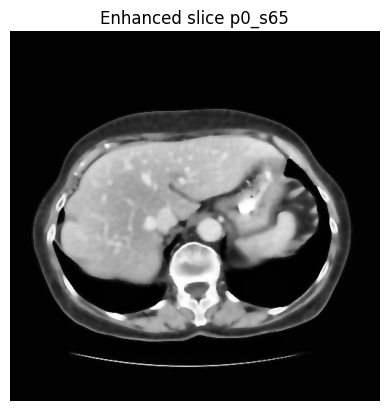

In [4]:
# Chapter 7 (slide 19): read the image -> show it
plt.figure()
plt.imshow(img, cmap='gray')
plt.title('Enhanced slice ' + slice_id)
plt.axis('off')
plt.show()

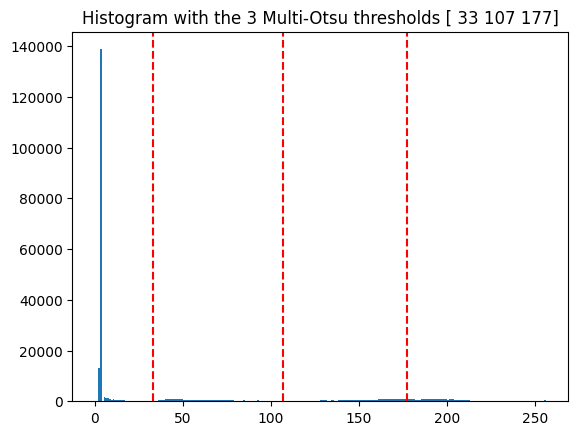

In [5]:
# look at the histogram to pick the thresholds: it has several peaks (multimodal, Chapter 7 slide 24),
# so one threshold is not enough. Multi-Otsu finds 3 thresholds automatically
# (Otsu is an extension of the Chapter 7 global thresholding, it is not in the slides)
thresholds = threshold_multiotsu(img, classes=4)

plt.figure()
plt.hist(img.ravel(), bins=256, range=(0, 256))
for t in thresholds:
    plt.axvline(t, color='red', linestyle='--')
plt.title('Histogram with the 3 Multi-Otsu thresholds ' + str(thresholds))
plt.show()

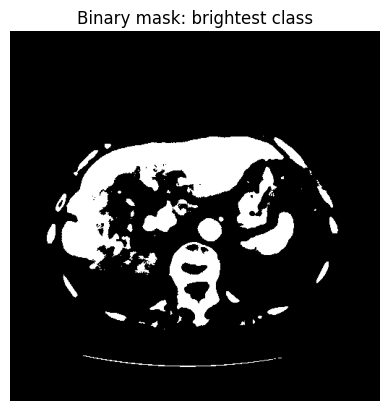

In [6]:
# makes a binary image: all pixels above the highest threshold are 1 (white), the rest 0 (black)
rough = (img > thresholds[2]).astype(np.uint8)

plt.figure()
plt.imshow(rough, cmap='gray')
plt.title('Binary mask: brightest class')
plt.axis('off')
plt.show()

**Morphology:** erosion shrinks, dilation grows, opening (erode then dilate) removes specks, closing (dilate then erode) fills holes.

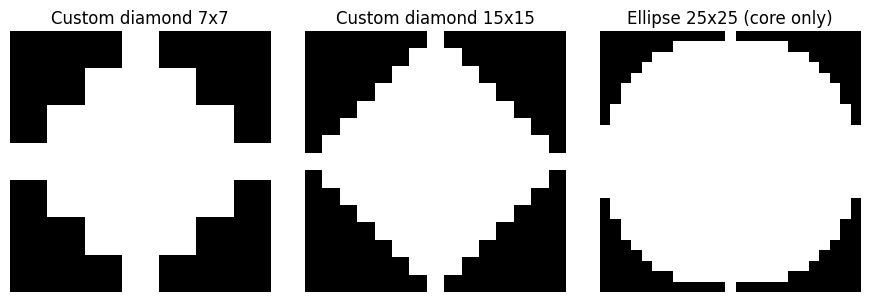

In [7]:
# Chapter 8: structuring elements
def diamond(n):
    # hand-made diamond: |row - centre| + |col - centre| <= radius. Its pointed corners cut the thin
    # diagonal bridges between the liver and its neighbours (stomach, heart) better than a round element
    c = n // 2
    se = np.zeros((n, n), dtype=np.uint8)
    for r in range(n):
        for q in range(n):
            if abs(r - c) + abs(q - c) <= c:
                se[r, q] = 1
    return se

SE_DIAMOND_7 = diamond(7)                  # final opening (removes specks)
SE_DIAMOND_15 = diamond(15)                # marker separation + Multi-Otsu closing
SE_ELLIPSE_25 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (25, 25))   # only for the big "solid liver core" opening

se_list = [SE_DIAMOND_7, SE_DIAMOND_15, SE_ELLIPSE_25]
se_titles = ["Custom diamond 7x7", "Custom diamond 15x15", "Ellipse 25x25 (core only)"]
fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for i in range(3):
    ax[i].imshow(se_list[i], cmap="gray")
    ax[i].set_title(se_titles[i])
    ax[i].axis("off")
plt.tight_layout()
plt.show()

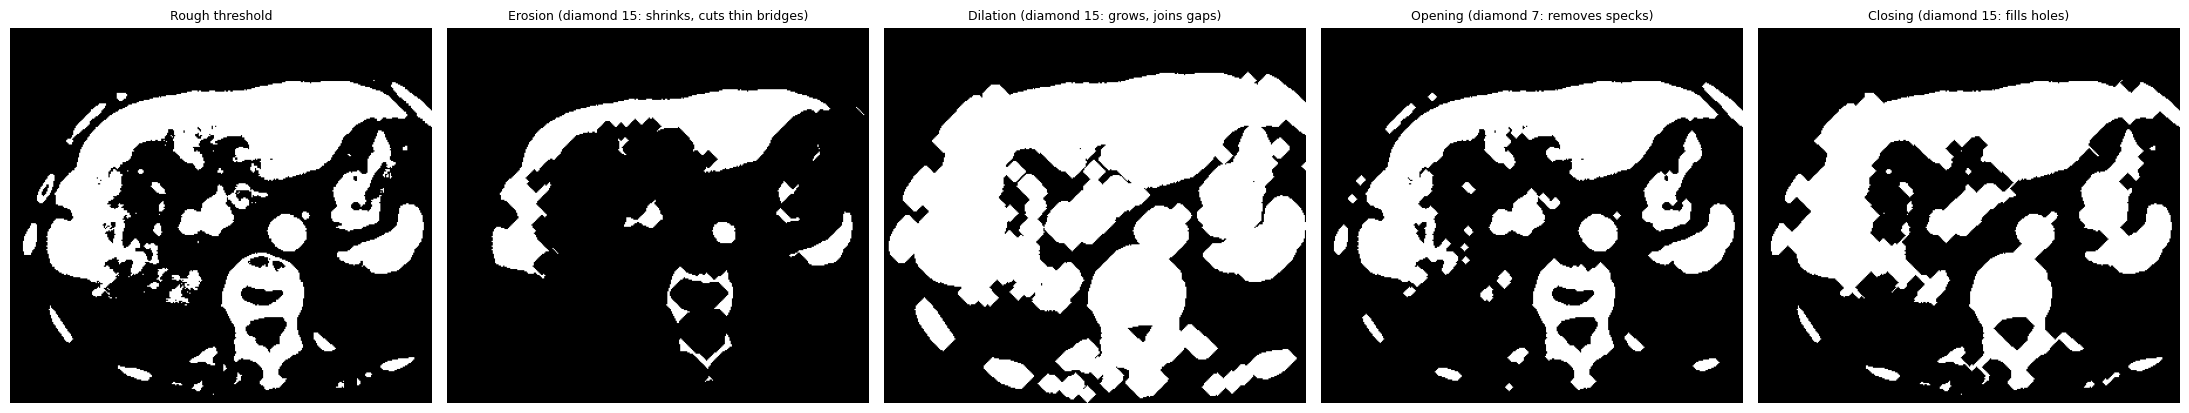

In [8]:
# Chapter 8: erosion, dilation, opening and closing on the rough binary mask
rough = (img > threshold_multiotsu(img, classes=4)[2]).astype(np.uint8)   # a rough bright-tissue mask
eroded = cv2.erode(rough, SE_DIAMOND_15)                                   # shrinks, cuts thin bridges
dilated = cv2.dilate(rough, SE_DIAMOND_15)                                 # grows, joins gaps
opened = cv2.morphologyEx(rough, cv2.MORPH_OPEN, SE_DIAMOND_7)             # erode then dilate: removes specks
closed = cv2.morphologyEx(rough, cv2.MORPH_CLOSE, SE_DIAMOND_15)           # dilate then erode: fills holes

# save the comparison figure for the report
morph_images = [rough, eroded, dilated, opened, closed]
morph_titles = ["Rough threshold",
                "Erosion (diamond 15: shrinks, cuts thin bridges)",
                "Dilation (diamond 15: grows, joins gaps)",
                "Opening (diamond 7: removes specks)",
                "Closing (diamond 15: fills holes)"]
fig, ax = plt.subplots(1, 5, figsize=(22, 5))
for i in range(5):
    ax[i].imshow(morph_images[i][100:420, 40:400], cmap="gray")
    ax[i].set_title(morph_titles[i], fontsize=9)
    ax[i].axis("off")
plt.tight_layout()
plt.savefig(FIGS + "/" + NAME + "_p2_morphology.png", dpi=120)
plt.show()

**Method A:** Multi-Otsu splits the image into 4 brightness classes; the brightest class holds the liver (and other organs), so morphology + `keep_liver` keep only the liver blob.

In [9]:
# Method A: Multi-Otsu thresholding (extension of Chapter 7) + morphology (Chapter 8)
def segment_multiotsu(img):
    t = threshold_multiotsu(img, classes=4)                 # 3 thresholds -> 4 brightness classes
    mask = (img > t[2]).astype(np.uint8)                    # brightest class (liver, spleen, kidneys, bone...)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, SE_DIAMOND_7)    # opening: cut thin links to other organs
    mask = keep_liver(mask)                                  # keep the liver blob only
    mask = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_CLOSE, SE_DIAMOND_15)  # closing: smooth the edge
    return ndi.binary_fill_holes(mask > 0)                   # Chapter 8: fill vessels / holes inside

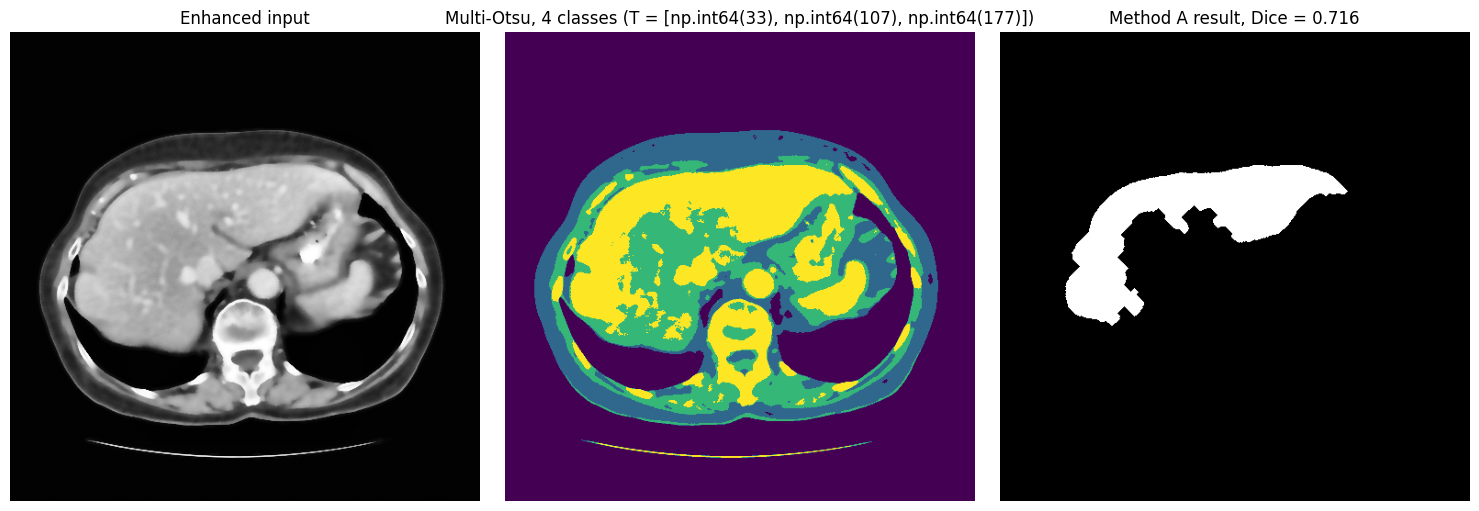

In [10]:
t = threshold_multiotsu(img, classes=4)
classes = np.digitize(img, bins=t)          # label every pixel 0, 1, 2 or 3 by its class
pred_a = segment_multiotsu(img)

# save the comparison figure for the report
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img, cmap="gray")
ax[0].set_title("Enhanced input")
ax[1].imshow(classes, cmap="viridis")
ax[1].set_title(f"Multi-Otsu, 4 classes (T = {list(t)})")
ax[2].imshow(pred_a, cmap="gray")
ax[2].set_title(f"Method A result, Dice = {dice(pred_a, gt):.3f}")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.savefig(FIGS + "/" + NAME + "_p2_method_a_multiotsu.png", dpi=120)
plt.show()

**Method B:** markers = sure liver (solid core) and sure background (dark tissue + other organs); watershed floods the edge image from both, and the boundary forms where they meet.

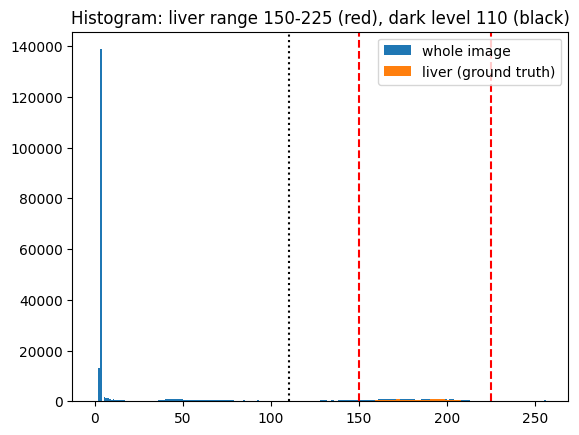

In [11]:
# Chapter 7: pick the liver range from the histogram of the true liver pixels
LIVER_LOW = 150      # liver brightness range after Phase 1 (from the liver histogram)
LIVER_HIGH = 225
DARK = 110           # fat / air / muscle are darker than this

plt.figure()
plt.hist(img.ravel(), bins=256, range=(0, 256), label='whole image')
plt.hist(img[gt].ravel(), bins=256, range=(0, 256), label='liver (ground truth)')
plt.axvline(LIVER_LOW, color='red', linestyle='--')
plt.axvline(LIVER_HIGH, color='red', linestyle='--')
plt.axvline(DARK, color='black', linestyle=':')
plt.title('Histogram: liver range 150-225 (red), dark level 110 (black)')
plt.legend()
plt.show()

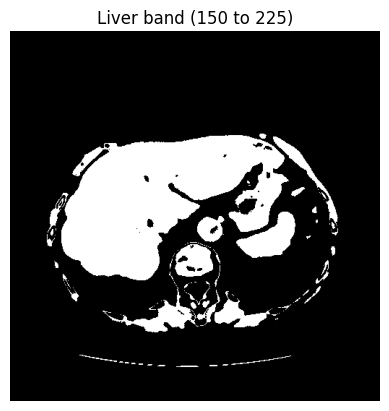

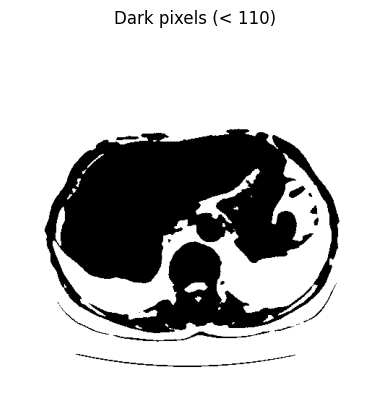

In [12]:
# makes a binary image, like roicolor(I, 150, 225) in the lecture:
# all pixels in (150, 225) are 1 and white, the rest is 0 and black
band = ((img >= LIVER_LOW) & (img <= LIVER_HIGH)).astype(np.uint8)
dark_pixels = img < DARK

plt.figure()
plt.imshow(band, cmap='gray')
plt.title('Liver band (150 to 225)')
plt.axis('off')
plt.show()

plt.figure()
plt.imshow(dark_pixels, cmap='gray')
plt.title('Dark pixels (< 110)')
plt.axis('off')
plt.show()

In [13]:
# Method B: marker-controlled watershed (extension of Chapter 7, not in the slides)
def segment_watershed(img, return_steps=False):
    band = ((img >= LIVER_LOW) & (img <= LIVER_HIGH)).astype(np.uint8)

    # 1. "sure liver" marker: a big opening (Chapter 8) keeps only the solid core of the liver
    core = cv2.morphologyEx(band, cv2.MORPH_OPEN, SE_ELLIPSE_25)
    core = keep_liver(core)

    # 2. "sure background" marker: dark pixels + other bright organs away from the liver core
    near_core = cv2.dilate(core.astype(np.uint8), SE_DIAMOND_15).astype(bool)
    other_bright = (band.astype(bool) & ~near_core).astype(np.uint8)
    other_organs = cv2.morphologyEx(other_bright, cv2.MORPH_OPEN, SE_DIAMOND_15) > 0
    square_3 = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
    dark = cv2.morphologyEx((img < DARK).astype(np.uint8), cv2.MORPH_OPEN, square_3) > 0
    markers = np.zeros(img.shape, np.int32)
    markers[dark | other_organs] = 1                        # label 1 = background
    markers[core] = 2                                       # label 2 = liver

    # 3. Gaussian smoothing + Sobel edges (Chapter 3), then flood the gradient image from the markers;
    #    the two floods meet on the strongest edges
    blurred = cv2.GaussianBlur(img, (5, 5), 0)
    gradient = sobel(blurred / 255.0)
    labels = watershed(gradient, markers)

    # 4. clean up: opening, keep the liver blob, fill holes (Chapter 8)
    mask = cv2.morphologyEx((labels == 2).astype(np.uint8), cv2.MORPH_OPEN, SE_DIAMOND_7) > 0
    mask = ndi.binary_fill_holes(keep_liver(mask))
    if return_steps:
        return mask, markers, gradient
    else:
        return mask

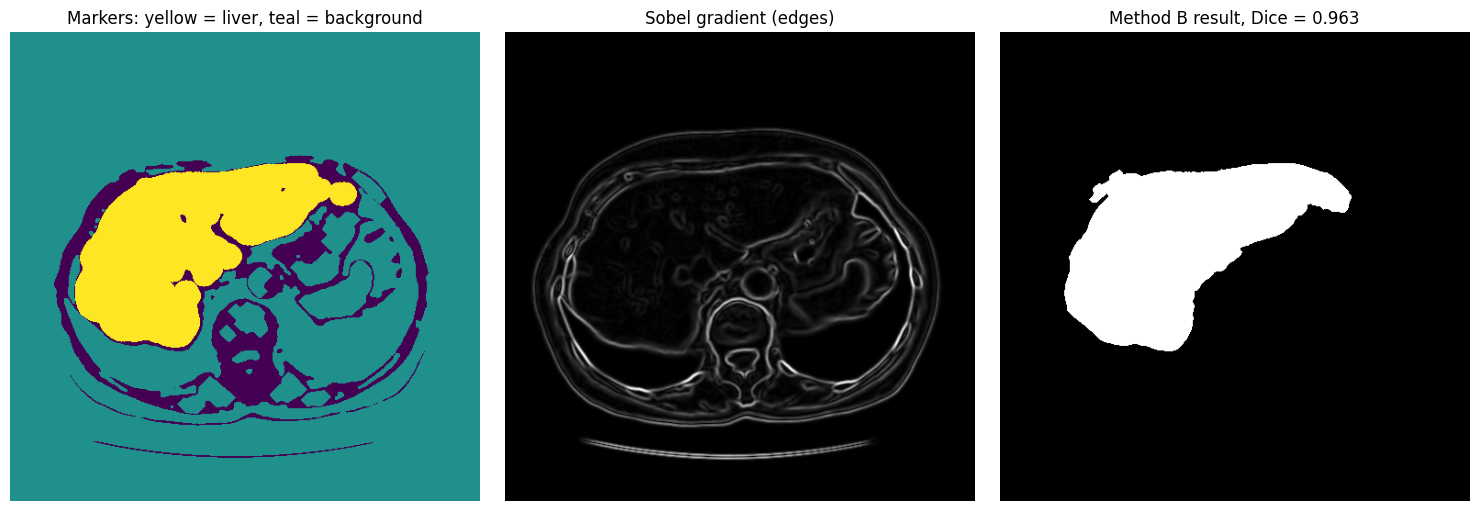

In [14]:
pred_b, markers, gradient = segment_watershed(img, return_steps=True)

# save the comparison figure for the report
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(markers, cmap="viridis")
ax[0].set_title("Markers: yellow = liver, teal = background")
ax[1].imshow(gradient, cmap="gray")
ax[1].set_title("Sobel gradient (edges)")
ax[2].imshow(pred_b, cmap="gray")
ax[2].set_title(f"Method B result, Dice = {dice(pred_b, gt):.3f}")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.savefig(FIGS + "/" + NAME + "_p2_method_b_watershed.png", dpi=120)
plt.show()

In [15]:
# run both methods on every slice, save the masks and the Dice / IoU scores
methods = ["multiotsu", "watershed"]
metric_rows = []
for f in files:
    slice_id, enhanced_img, gt_mask = load(f)
    for method in methods:
        if method == "multiotsu":
            pred_mask = segment_multiotsu(enhanced_img)
        else:
            pred_mask = segment_watershed(enhanced_img)
        cv2.imwrite(OUT + "/" + method + "/" + slice_id + "_liver_pred.png", pred_mask.astype(np.uint8) * 255)
        row = {}
        row["slice"] = slice_id
        row["method"] = method
        row["Dice"] = dice(pred_mask, gt_mask)
        row["IoU"] = iou(pred_mask, gt_mask)
        row["GT liver pixels"] = int(gt_mask.sum())
        metric_rows.append(row)

results = pd.DataFrame(metric_rows)
results.to_csv(OUT + "/phase2_metrics.csv", index=False)

summary = results.groupby("method")[["Dice", "IoU"]].agg(["mean", "std", "min"])
print(summary.round(3))
print("\nPer slice Dice:")
per_slice = results.pivot(index="slice", columns="method", values="Dice")
print(per_slice.round(3))

            Dice                  IoU              
            mean    std    min   mean    std    min
method                                             
multiotsu  0.795  0.224  0.000  0.696  0.216  0.000
watershed  0.914  0.077  0.679  0.849  0.116  0.514

Per slice Dice:
method  multiotsu  watershed
slice                       
p0_s46      0.000      0.893
p0_s56      0.835      0.870
p0_s57      0.781      0.893
p0_s58      0.758      0.895
p0_s59      0.780      0.924
p0_s60      0.919      0.927
p0_s61      0.949      0.959
p0_s62      0.803      0.967
p0_s65      0.716      0.963
p0_s66      0.825      0.959
p0_s67      0.931      0.974
p0_s68      0.908      0.976
p0_s69      0.949      0.969
p0_s70      0.876      0.948
p0_s71      0.900      0.823
p0_s72      0.787      0.679


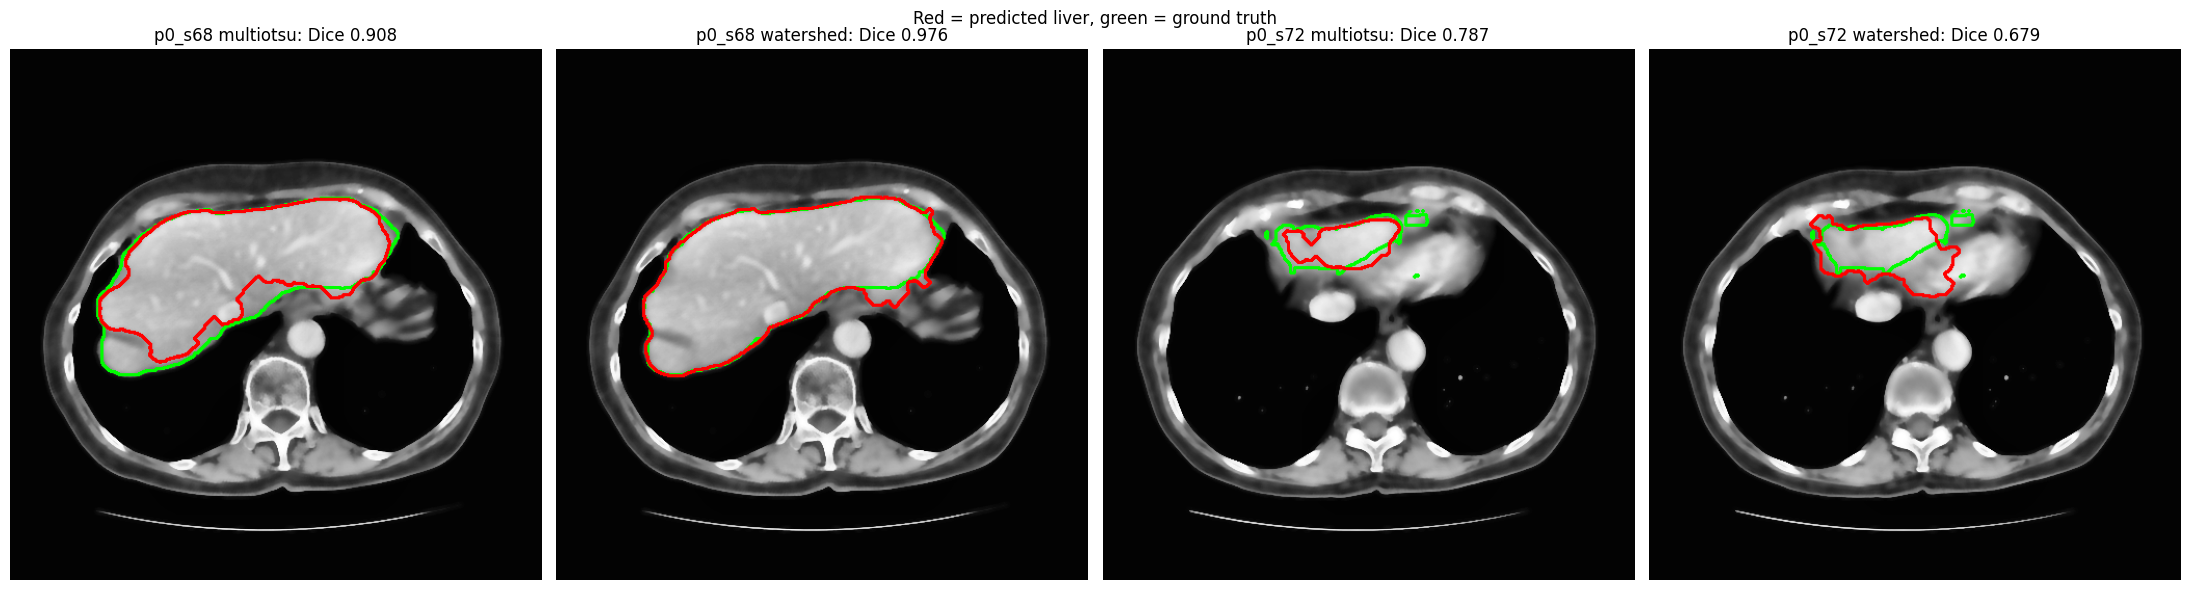

In [16]:
def overlay(img, pred_mask, gt_mask):
    # draw the contours: green = ground truth, red = predicted
    rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    contours, _ = cv2.findContours(gt_mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(rgb, contours, -1, (0, 255, 0), 2)
    contours, _ = cv2.findContours(pred_mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(rgb, contours, -1, (255, 0, 0), 2)
    return rgb

# best and worst slice of the watershed method
watershed_rows = results[results.method == "watershed"]
watershed_dice = watershed_rows.set_index("slice")["Dice"]
best_sid = watershed_dice.idxmax()
worst_sid = watershed_dice.idxmin()

# save the comparison figure for the report
panel_slices = [best_sid, best_sid, worst_sid, worst_sid]
panel_methods = ["multiotsu", "watershed", "multiotsu", "watershed"]
fig, ax = plt.subplots(1, 4, figsize=(22, 6))
for i in range(4):
    s = panel_slices[i]
    method = panel_methods[i]
    _, enhanced_img, gt_mask = load(ENH + "/" + s + "_enh.png")
    pred_mask = cv2.imread(OUT + "/" + method + "/" + s + "_liver_pred.png", 0) > 0
    ax[i].imshow(overlay(enhanced_img, pred_mask, gt_mask))
    ax[i].axis("off")
    ax[i].set_title(f"{s} {method}: Dice {dice(pred_mask, gt_mask):.3f}")
plt.suptitle("Red = predicted liver, green = ground truth")
plt.tight_layout()
plt.savefig(FIGS + "/" + NAME + "_p2_overlays.png", dpi=120)
plt.show()

In [17]:
# ---- failed cases: every slice where the final method scored Dice < 0.7, with MEASURED reasons ----
method_means = results.groupby("method")["Dice"].mean()
best_method = method_means.idxmax()
best = results[results.method == best_method].sort_values("Dice")
failed = best[best.Dice < 0.7]


def first_step(img):
    # the "sure liver" marker of the watershed
    band = ((img >= LIVER_LOW) & (img <= LIVER_HIGH)).astype(np.uint8)
    core = cv2.morphologyEx(band, cv2.MORPH_OPEN, SE_ELLIPSE_25)
    return keep_liver(core)


def hu(ct, mask):
    # median HU inside a mask
    if mask.any():
        return float(np.median(ct[mask]))
    else:
        return float("nan")


def diagnose(slice_id, img, pred_mask, gt_mask):
    # measure why the slice failed: size, contrast in HU, position, and which pipeline step went wrong
    ct = np.load(GT + "/" + slice_id + "_ct.npy")
    missed = gt_mask & ~pred_mask
    leaked = pred_mask & ~gt_mask
    reasons = []

    # Chapter 8: dilate the liver, then remove it -> the tissue just outside the liver
    square_15 = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 15))
    ref = cv2.dilate(gt_mask.astype(np.uint8), square_15).astype(bool) & ~gt_mask
    if gt_mask.sum() < 5000:
        reasons.append(f"small liver cross-section ({int(gt_mask.sum())} px): near the dome or tip, partial volume with neighbours")

    start = first_step(img)
    if not (start & gt_mask).any():
        reasons.append("step that failed: sure-liver marker (core) (nothing started on the liver)")
    elif not (pred_mask & gt_mask).any():
        reasons.append("step that failed: clean-up after sure-liver marker (core) removed everything it found on the liver")
    elif leaked.sum() >= missed.sum():
        reasons.append(f"step that failed: watershed leaked {int(leaked.sum())} px into tissue of {hu(ct, leaked):.0f} HU "
                       f"(liver {hu(ct, gt_mask):.0f} HU, neighbours {hu(ct, ref):.0f} HU): similar HU, no edge to stop at")
    else:
        reasons.append(f"step that failed: watershed stopped early, missed {int(missed.sum())} px of {hu(ct, missed):.0f} HU "
                       f"(found part {hu(ct, pred_mask & gt_mask):.0f} HU)")
    return "; ".join(reasons), ct, missed, leaked, ref

In [18]:
# write the failed-case table and a diagnosis figure for the 3 worst slices
lines = []
lines.append(f"# Phase 2 failed cases: {NAME} (liver segmentation)")
lines.append("")
lines.append(f"Final method: **{best_method}** (mean Dice {best.Dice.mean():.3f}). Slices with Dice < 0.7: {len(failed)} of {len(best)}.")
lines.append("")
lines.append("| Slice | Dice (" + best_method + ") | Ground-truth pixels | Predicted pixels | Measured reasons |")
lines.append("|---|---|---|---|---|")

k = 0
for _, row in failed.iterrows():
    _, enhanced_img, gt_mask = load(ENH + "/" + row.slice + "_enh.png")
    pred_mask = cv2.imread(OUT + "/" + best_method + "/" + row.slice + "_liver_pred.png", 0) > 0
    why, ct, missed, leaked, ref = diagnose(row.slice, enhanced_img, pred_mask, gt_mask)
    lines.append(f"| {row.slice} | {row.Dice:.3f} | {int(gt_mask.sum())} | {int(pred_mask.sum())} | {why} |")

    if k < 3:                                                   # diagnosis figure for the 3 worst slices
        # crop around the liver with a 30 pixel border
        ys, xs = np.where(gt_mask | pred_mask)
        y0 = max(ys.min() - 30, 0)
        y1 = ys.max() + 30
        x0 = max(xs.min() - 30, 0)
        x1 = xs.max() + 30
        fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
        ax[0].imshow(overlay(enhanced_img, pred_mask, gt_mask)[y0:y1, x0:x1])
        ax[0].axis("off")
        ax[0].set_title(f"{row.slice}: red = predicted, green = truth (Dice {row.Dice:.3f})")

        # HU histograms of the truth, the surroundings, the missed and the leaked pixels
        hist_masks = [gt_mask, ref, missed, leaked]
        hist_names = ["liver (truth)", "surrounding tissue", "missed", "leaked"]
        hist_colours = ["green", "grey", "orange", "red"]
        for i in range(4):
            mask = hist_masks[i]
            if mask.any():
                ax[1].hist(ct[mask], bins=60, range=(-100, 250), alpha=0.5, density=True,
                           label=f"{hist_names[i]} ({int(mask.sum())} px)", color=hist_colours[i])
        ax[1].set_xlabel("HU")
        ax[1].set_ylabel("density")
        ax[1].legend(fontsize=8)
        ax[1].set_title("HU histograms")
        plt.tight_layout()
        plt.savefig(FAILED + "/" + NAME + "_" + row.slice + "_" + best_method + "_diagnosis.png", dpi=110)
        plt.close()
    k = k + 1

if failed.empty:
    lines.append("| - | - | - | - | no slice below 0.7 |")
lines.append("")
lines.append("Diagnosis figures (overlay + HU histograms of truth, surroundings, missed and leaked pixels) for the 3 worst slices are saved next to this file.")

report_text = "\n".join(lines)
with open(FAILED + "/" + NAME + "_phase2_failed_cases.md", "w") as fh:
    fh.write(report_text)
print(report_text)

# Phase 2 failed cases: sama (liver segmentation)

Final method: **watershed** (mean Dice 0.914). Slices with Dice < 0.7: 1 of 16.

| Slice | Dice (watershed) | Ground-truth pixels | Predicted pixels | Measured reasons |
|---|---|---|---|---|
| p0_s72 | 0.679 | 4641 | 7110 | small liver cross-section (4641 px): near the dome or tip, partial volume with neighbours; step that failed: watershed leaked 3120 px into tissue of 103 HU (liver 112 HU, neighbours 45 HU): similar HU, no edge to stop at |

Diagnosis figures (overlay + HU histograms of truth, surroundings, missed and leaked pixels) for the 3 worst slices are saved next to this file.


**Parameter sensitivity.** The key parameter of the final method, **DARK** (pixels darker than this become 'sure background' markers for the watershed), is varied while everything else stays fixed; the mean Dice over all test slices shows how sensitive the result is and whether the chosen value sits on a plateau or a sharp peak.

In [19]:
# ---- parameter sensitivity: mean Dice of the final method while DARK changes ----
chosen = DARK
sweep_rows = []
for value in [80, 90, 100, 110, 120, 130, 140]:
    DARK = value                                         # the segmentation function reads this setting
    scores = []
    for f in files:
        slice_id, enhanced_img, gt_mask = load(f)
        scores.append(dice(segment_watershed(enhanced_img), gt_mask))
    row = {}
    row["DARK"] = value
    row["mean Dice"] = np.mean(scores)
    row["std Dice"] = np.std(scores)
    sweep_rows.append(row)
DARK = chosen                                            # put the chosen value back

sweep = pd.DataFrame(sweep_rows)
sweep.to_csv(OUT + "/phase2_sensitivity.csv", index=False)
print(sweep.round(3).to_string(index=False))

 DARK  mean Dice  std Dice
   80      0.894     0.071
   90      0.902     0.073
  100      0.907     0.073
  110      0.914     0.074
  120      0.918     0.070
  130      0.920     0.068
  140      0.919     0.066


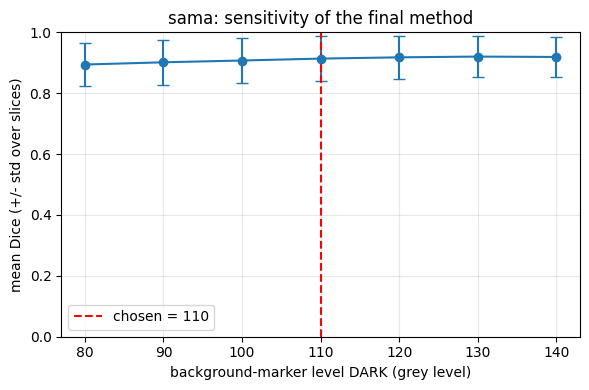

In [20]:
# save the sensitivity figure for the report
plt.figure(figsize=(6, 4))
plt.errorbar(sweep["DARK"], sweep["mean Dice"], yerr=sweep["std Dice"], marker="o", capsize=4)
plt.axvline(chosen, color="red", linestyle="--", label=f"chosen = {chosen}")
plt.xlabel("background-marker level DARK (grey level)")
plt.ylabel("mean Dice (+/- std over slices)")
plt.ylim(0, 1)
plt.title(f"{NAME}: sensitivity of the final method")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGS + "/" + NAME + "_p2_sensitivity.png", dpi=120)
plt.show()